# Neurosymbolic RL experiments: reward machines and LLM-written task specifications

**Experiment 1.** Does task structure given as a *reward machine* help a tabular Q-learning agent, and is it the
symbolic structure that helps or just the task knowledge? Conditions:

| Condition | Agent memory | Reward signal | Task knowledge |
|---|---|---|---|
| `flat` | which events have been seen (generic) | true sparse reward | none |
| `flat+numeric` (control) | same as `flat` | true reward + hand-written numeric shaping | as numbers |
| `rm` | reward machine state | reward machine | as an automaton |
| `rm+shaping` | reward machine state | reward machine + automatic shaping from the machine | as an automaton |
| `crm` | reward machine state | reward machine, counterfactual updates | as an automaton |
| `crm-swap`, `crm-noavoid` | corrupted machine | corrupted machine | wrong automaton |

**Experiment 2.** An LLM writes the reward machine from a plain-English task description. We check each one for exact
equivalence with the true machine and train agents on the generated machines.

The environment is a re-implementation (code is th same really) in the style of the OfficeWorld domain of Toro Icarte et al. (JAIR 2022),
with our my map.

In [ ]:
QUICK = False
SAVE_TO_DRIVE = False   x

SEEDS        = 3 if QUICK else 10
TOTAL_STEPS  = 20_000 if QUICK else 150_000
EVAL_EVERY   = 2_000 if QUICK else 2_500
HORIZON      = 100          # max steps per episode
GAMMA, ALPHA, EPSILON = 0.9, 0.5, 0.1
N_EVAL_STARTS = 10          # fixed start cells used for evaluation

import os, json, re, time, random, itertools, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

RESULTS_DIR = "results"
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = "/content/drive/MyDrive/nsrl_results"
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Saving results to", RESULTS_DIR)

## 1. Environment
A 12 x 9 grid of twelve 3 x 3 rooms. Doors sit in the middle of each shared wall. Events: `a`-`d` (corner rooms),
`e` (coffee, two machines), `f` (mail), `g` (office), `n` (decorations, which must be avoided).

In [ ]:
W, H = 12, 9
PROPS = {
    'a': [(1, 1)], 'b': [(10, 1)], 'c': [(10, 7)], 'd': [(1, 7)],
    'e': [(4, 1), (7, 7)], 'f': [(7, 4)], 'g': [(4, 4)],
    'n': [(1, 4), (10, 4), (7, 1), (4, 7)],
}
EVENTS = list(PROPS)                         # alphabet of high-level events
CELL_PROP = {c: p for p, cs in PROPS.items() for c in cs}
MOVES = [(0, -1), (1, 0), (0, 1), (-1, 0)]   # up, right, down, left
CELLS = [(x, y) for y in range(H) for x in range(W)]
CIDX = {c: i for i, c in enumerate(CELLS)}

def can_move(x, y, nx, ny):
    if not (0 <= nx < W and 0 <= ny < H):
        return False
    if x // 3 != nx // 3 and y % 3 != 1:   # crossing a vertical wall: only through the door row
        return False
    if y // 3 != ny // 3 and x % 3 != 1:   # crossing a horizontal wall: only through the door column
        return False
    return True

# Precomputed transition table: NEXT[cell_index, action] -> cell_index
NEXT = np.zeros((len(CELLS), 4), dtype=np.int64)
for i, (x, y) in enumerate(CELLS):
    for a, (dx, dy) in enumerate(MOVES):
        nx, ny = x + dx, y + dy
        NEXT[i, a] = CIDX[(nx, ny)] if can_move(x, y, nx, ny) else i
LABEL = [CELL_PROP.get(c) for c in CELLS]  # event observed in each cell (or None)
FREE = [i for i, c in enumerate(CELLS) if c not in CELL_PROP]

def bfs_dist(targets):
    """Shortest path length (in moves) from every cell to the nearest target cell."""
    d = np.full(len(CELLS), 10**6); q = collections.deque()
    for t in targets:
        d[CIDX[t]] = 0; q.append(CIDX[t])
    while q:                                  # moves are symmetric, so forward BFS gives distances
        i = q.popleft()
        for a in range(4):
            j = NEXT[i, a]
            if d[j] > d[i] + 1:
                d[j] = d[i] + 1; q.append(j)
    return d
DIST = {p: bfs_dist(cs) for p, cs in PROPS.items()}

def show_map():
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for x in range(W + 1):
        ax.plot([x, x], [0, H], color="#ddd", lw=0.5)
    for y in range(H + 1):
        ax.plot([0, W], [y, y], color="#ddd", lw=0.5)
    for i, (x, y) in enumerate(CELLS):          # walls
        if x % 3 == 2 and x < W - 1 and NEXT[i, 1] == i:
            ax.plot([x + 1, x + 1], [H - y - 1, H - y], color="k", lw=2)
        if y % 3 == 2 and y < H - 1 and NEXT[i, 2] == i:
            ax.plot([x, x + 1], [H - y - 1, H - y - 1], color="k", lw=2)
    ax.plot([0, W, W, 0, 0], [0, 0, H, H, 0], color="k", lw=2)
    for (x, y), p in CELL_PROP.items():
        ax.text(x + .5, H - y - .5, p, ha="center", va="center", fontsize=13,
                color="#C8283A" if p == "n" else "#1F5FD6", weight="bold")
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title("Office gridworld")
    plt.show()
show_map()

## 2. Reward machines
A reward machine maps (machine state, event) to (next machine state, reward). Any event without a listed transition
leaves the state unchanged with reward 0. Terminal states end the episode.

In [4]:
class RewardMachine:
    def __init__(self, u0, transitions, terminal):
        """transitions: list of (from, event, to, reward)."""
        self.u0, self.terminal = u0, set(terminal)
        self.delta = collections.defaultdict(dict)
        for u, ev, v, r in transitions:
            self.delta[u][ev] = (v, float(r))
        states = {u0} | set(self.terminal) | {u for u, *_ in transitions} | {v for _, _, v, _ in transitions}
        self.states = sorted(states, key=lambda s: (s != u0, str(s)))
        self.idx = {u: i for i, u in enumerate(self.states)}

    def step(self, u, event):
        if event is not None and event in self.delta.get(u, {}):
            return self.delta[u][event]
        return u, 0.0

    def dist_to_goal(self):
        """Fewest transitions from each state to a rewarding transition (inf if impossible)."""
        best = {u: np.inf for u in self.states}
        changed = True
        while changed:
            changed = False
            for u in self.states:
                if u in self.terminal:
                    continue
                for ev, (v, r) in self.delta.get(u, {}).items():
                    cand = 1 if r > 0 else (np.inf if v in self.terminal else 1 + best[v])
                    if cand < best[u]:
                        best[u], changed = cand, True
        return best

def rm(u0, transitions, terminal=("acc", "fail")):
    return RewardMachine(u0, transitions, terminal)

def avoid(states):   # every listed state fails on a decoration
    return [(u, "n", "fail", 0) for u in states]

TRUE_RM = {
    "coffee":      rm("u0", [("u0", "e", "u1", 0), ("u1", "g", "acc", 1)] + avoid(["u0", "u1"])),
    "mail":        rm("u0", [("u0", "f", "u1", 0), ("u1", "g", "acc", 1)] + avoid(["u0", "u1"])),
    "coffee_mail": rm("u0", [("u0", "e", "ue", 0), ("u0", "f", "uf", 0), ("ue", "f", "uef", 0),
                             ("uf", "e", "uef", 0), ("uef", "g", "acc", 1)] + avoid(["u0", "ue", "uf", "uef"])),
    "patrol":      rm("u0", [("u0", "a", "u1", 0), ("u1", "b", "u2", 0), ("u2", "c", "u3", 0),
                             ("u3", "d", "acc", 1)], terminal=("acc",)),
    # new tasks (our small "new dataset")
    "b_coffee":    rm("u0", [("u0", "b", "u1", 0), ("u1", "e", "u2", 0), ("u2", "g", "acc", 1)]
                             + avoid(["u0", "u1", "u2"])),
    "mail_home":   rm("u0", [("u0", "f", "u1", 0), ("u1", "g", "u2", 0), ("u2", "a", "acc", 1)]
                             + avoid(["u0", "u1", "u2"])),
}
ORIGINAL_TASKS = ["coffee", "mail", "coffee_mail", "patrol"]
NEW_TASKS = ["b_coffee", "mail_home"]

# hand-written numeric shaping for the control
#the same task knowledge as a distance function, no automaton.
#returns (targets, remaining) from the set of events seen so far.
def next_subgoal(task, seen):
    seq = {"coffee": ["e", "g"], "mail": ["f", "g"], "patrol": ["a", "b", "c", "d"],
           "b_coffee": ["b", "e", "g"], "mail_home": ["f", "g", "a"]}
    if task == "coffee_mail":
        missing = [p for p in "ef" if p not in seen]
        return (missing, len(missing) + 1) if missing else (["g"], 1)
    s = seq[task]
    for k, p in enumerate(s):
        if p not in seen:
            return [p], len(s) - k
    return [s[-1]], 1

NameError: name 'collections' is not defined

## 3. Corrupted machines (for the stress test)

In [ ]:
def corrupt_swap(m):
    """Swap the events on the first two progress transitions (e.g. 'coffee then office' becomes 'office then coffee')."""
    prog = [(u, ev) for u in m.states for ev, (v, r) in m.delta.get(u, {}).items() if v != "fail"]
    (u1, e1), (u2, e2) = prog[0], prog[1]
    trans = []
    for u in m.states:
        for ev, (v, r) in m.delta.get(u, {}).items():
            if (u, ev) == (u1, e1): ev = e2
            elif (u, ev) == (u2, e2): ev = e1
            trans.append((u, ev, v, r))
    return RewardMachine(m.u0, trans, m.terminal)

def corrupt_noavoid(m):
    """Drop every 'decoration -> fail' transition, so the machine no longer penalises decorations."""
    trans = [(u, ev, v, r) for u in m.states for ev, (v, r) in m.delta.get(u, {}).items() if ev != "n"]
    return RewardMachine(m.u0, trans, m.terminal)

## 4. Agents and training
Tabular Q-learning. Agents that use a reward machine learn only from *their* machine (so a wrong machine means a
wrong learning signal). Success is always measured against the *true* task.

In [1]:
EVENT_BIT = {p: 1 << i for i, p in enumerate("abcdefg")}

def run(task, cond, seed, agent_rm=None, steps=None):
    steps = steps or TOTAL_STEPS
    rng = np.random.default_rng(seed); prng = random.Random(seed)
    true_rm = TRUE_RM[task]
    uses_rm = cond.startswith("rm") or cond.startswith("crm")
    if uses_rm and agent_rm is None:
        agent_rm = {"crm-swap": corrupt_swap, "crm-noavoid": corrupt_noavoid}.get(cond, lambda m: m)(true_rm)
    n_mem = len(agent_rm.states) if uses_rm else 128
    Q = np.zeros((len(CELLS), n_mem, 4))

    # shaping potentials
    # Potential-based shaping, F = gamma * phi(next) - phi(current) (Ng et al. 1999). potentials are non-negative and
    # grow towards the goal, so progress is rewarded and wandering is not. Accepting states keep the top potential,
    # failure states get 0, so reaching the goal earns a bonus and failing costs one.
    if cond == "rm+shaping":
        dist = agent_rm.dist_to_goal()
        finite = [d for d in dist.values() if np.isfinite(d)]
        far = (max(finite) if finite else 0) + 1
        phi_u = {}
        for u in agent_rm.states:
            if u in agent_rm.terminal:
                phi_u[u] = 0.25 * far if u != "fail" else 0.0
            else:
                phi_u[u] = 0.25 * (far - (dist[u] if np.isfinite(dist[u]) else far))
    TMAX = 4 * 25 + 30          # largest value of (remaining * 25 + distance) on this map
    def phi_numeric(cell, seen, u_true=None):
        if u_true == "fail":
            return 0.0
        if u_true is not None and u_true in TRUE_RM[task].terminal:
            return 0.01 * TMAX
        targets, remaining = next_subgoal(task, seen)
        d = min(DIST[p][cell] for p in targets)
        return 0.01 * (TMAX - (remaining * 25 + d))

    eval_starts = random.Random(1234).sample(FREE, N_EVAL_STARTS)

    def greedy(q):
        m = q.max(); best = np.flatnonzero(q >= m - 1e-12)
        return int(best[prng.randrange(len(best))])

    def evaluate():
        succ, lens = 0, []
        for s0 in eval_starts:
            cell, u_true = s0, true_rm.u0
            mem = agent_rm.u0 if uses_rm else 0
            for t in range(HORIZON):
                mi = agent_rm.idx[mem] if uses_rm else mem
                cell = NEXT[cell, greedy(Q[cell, mi])]
                ev = LABEL[cell]
                u_true, r_true = true_rm.step(u_true, ev)
                if uses_rm:
                    mem, _ = agent_rm.step(mem, ev)
                elif ev in EVENT_BIT:
                    mem |= EVENT_BIT[ev]
                if r_true > 0:
                    succ += 1; lens.append(t + 1); break
                if u_true in true_rm.terminal or (uses_rm and mem in agent_rm.terminal):
                    break
        return succ / len(eval_starts), (np.mean(lens) if lens else np.nan)

    log, t = [], 0
    while t < steps:
        cell = FREE[prng.randrange(len(FREE))]
        u_true = true_rm.u0
        mem = agent_rm.u0 if uses_rm else 0
        seen = set()
        for _ in range(HORIZON):
            mi = agent_rm.idx[mem] if uses_rm else mem
            a = prng.randrange(4) if prng.random() < EPSILON else greedy(Q[cell, mi])
            ncell = NEXT[cell, a]; ev = LABEL[ncell]
            u_true, r_true = true_rm.step(u_true, ev)
            if cond.startswith("crm"):
                for u in agent_rm.states:            # counterfactual update for every machine state
                    if u in agent_rm.terminal:
                        continue
                    v, r = agent_rm.step(u, ev)
                    target = r if v in agent_rm.terminal else r + GAMMA * Q[ncell, agent_rm.idx[v]].max()
                    ui = agent_rm.idx[u]
                    Q[cell, ui, a] += ALPHA * (target - Q[cell, ui, a])
                mem, _ = agent_rm.step(mem, ev); done = mem in agent_rm.terminal
            elif uses_rm:
                v, r = agent_rm.step(mem, ev)
                if cond == "rm+shaping":
                    r += GAMMA * phi_u[v] - phi_u[mem]
                done = v in agent_rm.terminal
                vi = agent_rm.idx[v]
                target = r if done else r + GAMMA * Q[ncell, vi].max()
                Q[cell, mi, a] += ALPHA * (target - Q[cell, mi, a])
                mem = v
            else:
                nseen = seen | ({ev} if ev in EVENT_BIT else set())
                nmem = mem | EVENT_BIT.get(ev, 0)
                r = r_true
                done = u_true in true_rm.terminal
                if cond == "flat+numeric":
                    r += GAMMA * phi_numeric(ncell, nseen, u_true) - phi_numeric(cell, seen)
                target = r if done else r + GAMMA * Q[ncell, nmem].max()
                Q[cell, mi, a] += ALPHA * (target - Q[cell, mi, a])
                mem, seen = nmem, nseen
            cell = ncell; t += 1
            if t % EVAL_EVERY == 0:
                sr, ln = evaluate()
                log.append({"task": task, "cond": cond, "seed": seed, "step": t, "success": sr, "ep_len": ln})
            if done or t >= steps:
                break
    return log

## 5. Experiment 1: run

In [18]:
CONDS = ["flat", "flat+numeric", "rm", "rm+shaping", "crm", "crm-swap", "crm-noavoid"]
TASKS_EXP1 = ORIGINAL_TASKS + NEW_TASKS

rows, t0 = [], time.time()
for task in TASKS_EXP1:
    for cond in CONDS:
        if cond == "crm-noavoid" and task == "patrol":
            continue    # patrol has no decorations to drop
        for seed in range(SEEDS):
            rows += run(task, cond, seed)
    print(f"{task:12s} done  ({time.time() - t0:.0f}s)")
exp1 = pd.DataFrame(rows)
exp1.to_csv(f"{RESULTS_DIR}/exp1.csv", index=False)
print("rows:", len(exp1))

coffee       done  (186s)
mail         done  (368s)
coffee_mail  done  (598s)
patrol       done  (802s)
b_coffee     done  (1014s)
mail_home    done  (1227s)
rows: 24600


## 6. Experiment 1: results

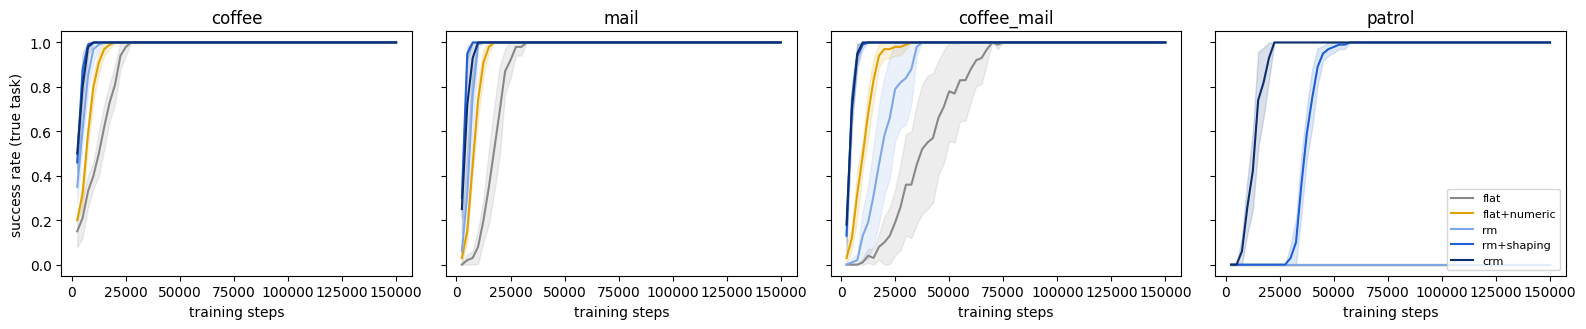

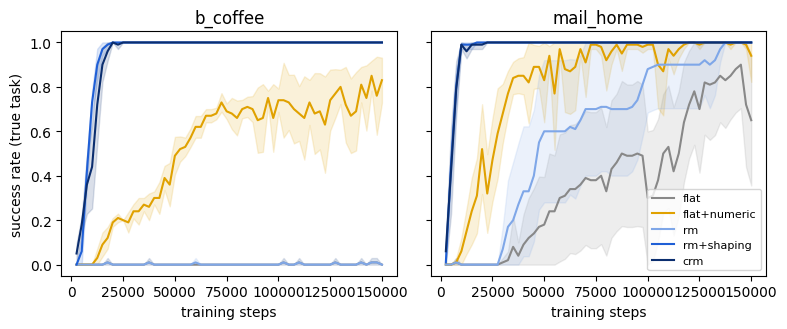

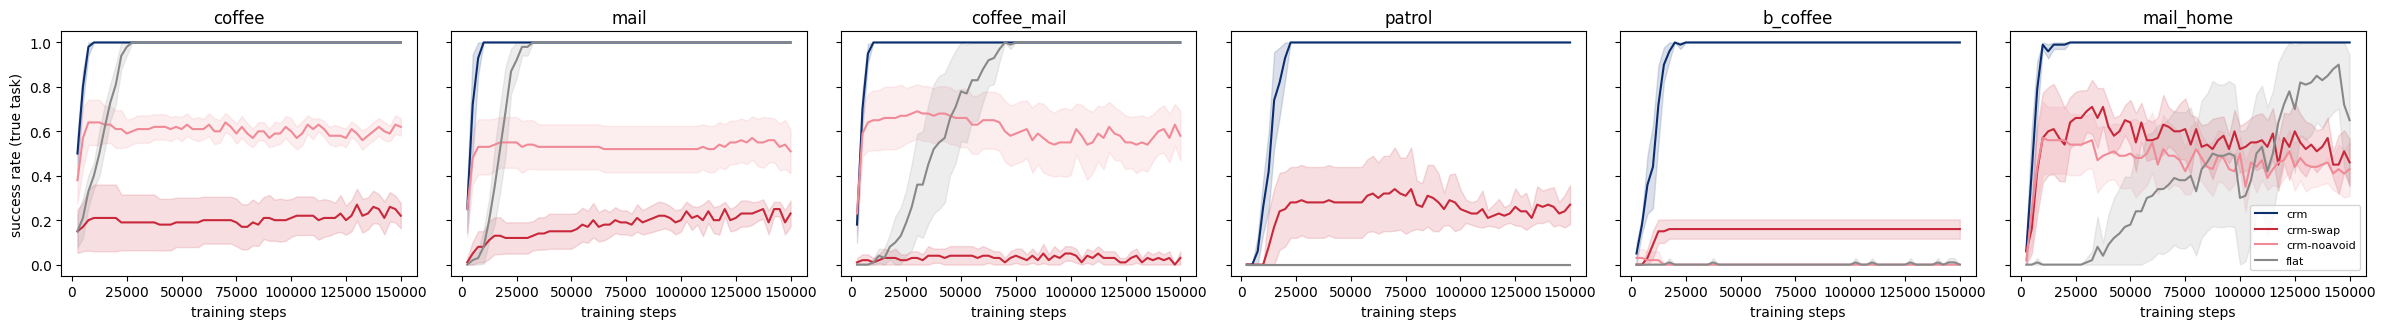

task,b_coffee,coffee,coffee_mail,mail,mail_home,patrol
cond,,,,,,
crm,1.00,1.00,1.00,1.00,1.00,1.00
crm-noavoid,0.00,0.62,0.58,0.51,0.43,NaN
crm-swap,0.16,0.22,0.03,0.23,0.46,0.27
flat,0.00,1.00,1.00,1.00,0.65,0.00
flat+numeric,0.83,1.00,1.00,1.00,0.94,0.00
rm,0.00,1.00,1.00,1.00,1.00,0.00
rm+shaping,1.00,1.00,1.00,1.00,1.00,1.00


In [19]:
COLORS = {"flat": "#888888", "flat+numeric": "#E0A100", "rm": "#7FA7E8", "rm+shaping": "#1F5FD6",
          "crm": "#0B2E6F", "crm-swap": "#C8283A", "crm-noavoid": "#F08A96"}

def curves(df, tasks, conds, fname):
    fig, axes = plt.subplots(1, len(tasks), figsize=(4 * len(tasks), 3.4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, task in zip(axes, tasks):
        for cond in conds:
            d = df[(df.task == task) & (df.cond == cond)]
            if d.empty:
                continue
            g = d.groupby("step").success
            m, s, n = g.mean(), g.std().fillna(0), g.count()
            ci = 1.96 * s / np.sqrt(n)
            ax.plot(m.index, m.values, label=cond, color=COLORS.get(cond))
            ax.fill_between(m.index, (m - ci).clip(0, 1).values, (m + ci).clip(0, 1).values, alpha=0.15, color=COLORS.get(cond))
        ax.set_title(task); ax.set_xlabel("training steps"); ax.set_ylim(-0.05, 1.05)
    axes[0].set_ylabel("success rate (true task)")
    axes[-1].legend(fontsize=8, loc="lower right")
    plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/{fname}", dpi=200); plt.show()

curves(exp1, ORIGINAL_TASKS, ["flat", "flat+numeric", "rm", "rm+shaping", "crm"], "exp1_main.png")
curves(exp1, NEW_TASKS, ["flat", "flat+numeric", "rm", "rm+shaping", "crm"], "exp1_newtasks.png")
curves(exp1, ORIGINAL_TASKS + NEW_TASKS, ["crm", "crm-swap", "crm-noavoid", "flat"], "exp1_corrupted.png")

def summary(df):
    out = []
    for (task, cond), d in df.groupby(["task", "cond"]):
        per_seed = []
        for seed, ds in d.groupby("seed"):
            hit = ds[ds.success >= 0.9]
            per_seed.append(hit.step.min() if len(hit) else np.nan)
        final = d[d.step == d.step.max()].success
        out.append({"task": task, "cond": cond,
                    "final_success": round(final.mean(), 2),
                    "steps_to_90%": (np.nanmedian(per_seed) if not np.all(np.isnan(per_seed)) else np.nan),
                    "seeds_reaching_90%": f"{int(np.sum(~np.isnan(per_seed)))}/{len(per_seed)}"})
    return pd.DataFrame(out)

table1 = summary(exp1)
table1.to_csv(f"{RESULTS_DIR}/exp1_summary.csv", index=False)
table1.pivot(index="cond", columns="task", values="final_success")

In [20]:
table1.pivot(index="cond", columns="task", values="steps_to_90%")

task,b_coffee,coffee,coffee_mail,mail,mail_home,patrol
cond,,,,,,
crm,15000.0,7500.0,7500.0,5000.0,7500.0,16250.0
crm-noavoid,NaN,7500.0,7500.0,NaN,NaN,NaN
crm-swap,NaN,NaN,NaN,NaN,25000.0,15000.0
flat,NaN,21250.0,42500.0,21250.0,87500.0,NaN
flat+numeric,102500.0,12500.0,16250.0,12500.0,32500.0,NaN
rm,NaN,7500.0,21250.0,8750.0,48750.0,NaN
rm+shaping,12500.0,5000.0,7500.0,5000.0,8750.0,42500.0


## 7. Experiment 2: LLM-written reward machines
Set `LLM_MODE`:
* `"anthropic"`: calls the API. Add your key in Colab under the key icon (Secrets) as `ANTHROPIC_API_KEY`.
* `"manual"`: prints the prompts; paste each answer into `MANUAL_RESPONSES` (free, using any chat interface).

Cost for the default settings (6 tasks x 5 samples) is a few cents.

In [28]:
# code from partly from ASP-BENCH,
# !pip install -q anthropic

LLM_MODE = "anthropic"                 # "anthropic" or "manual"
LLM_MODEL = "claude-sonnet-5"
SAMPLES_PER_TASK = 5
TEMPERATURE = 1.0

TASK_TEXT = {
    "coffee":      "Get a coffee and deliver it to the office. Never step on a decoration.",
    "mail":        "Pick up the mail and deliver it to the office. Never step on a decoration.",
    "coffee_mail": "Get a coffee and pick up the mail, in either order, then deliver both to the office. "
                   "Never step on a decoration.",
    "patrol":      "Patrol the building: visit room A, then room B, then room C, then room D, in that order.",
    "b_coffee":    "First check in at room B, then get a coffee, then bring it to the office. "
                   "Never step on a decoration.",
    "mail_home":   "Pick up the mail, deliver it to the office, and then go back to room A. "
                   "Never step on a decoration.",
}

PROMPT = """You are specifying a task for a reinforcement learning agent as a reward machine.

The agent walks around an office. At each step it observes at most one event:
  a, b, c, d : the agent is in room A, B, C or D
  e          : the agent is at a coffee machine (picks up coffee)
  f          : the agent is at the mail room (picks up mail)
  g          : the agent is at the office
  n          : the agent stepped on a decoration

A reward machine has states and transitions. Each transition goes from a state, on one event, to a state, with a reward.
If an event has no transition from the current state, the machine stays in the same state with reward 0.
Give reward 1 on the transition that completes the task, and 0 on every other transition.
If the task forbids something, add a transition to a terminal state called "fail" with reward 0.
The state where the task is complete must be a terminal state called "acc".

Task: {task}

Answer with JSON only, in exactly this format:
{{"initial_state": "u0",
 "terminal_states": ["acc", "fail"],
 "transitions": [{{"from": "u0", "event": "e", "to": "u1", "reward": 0}}, ...]}}
"""

def build_prompt(task):
    return PROMPT.format(task=TASK_TEXT[task])

MANUAL_RESPONSES = {task: [] for task in TASK_TEXT}   # paste answers here in manual mode, e.g.
# MANUAL_RESPONSES["coffee"] = ['{"initial_state": "u0", ...}', ...]

def call_llm(prompt):
    import anthropic
    try:
        from google.colab import userdata
        key = userdata.get("ANTHROPIC_API_KEY")
    except Exception:
        key = os.environ.get("ANTHROPIC_API_KEY")
    client = anthropic.Anthropic(api_key=key)
    msg = client.messages.create(model=LLM_MODEL, max_tokens=1500,
                                 messages=[{"role": "user", "content": prompt}])
    return "".join(b.text for b in msg.content if b.type == "text")

def collect_responses():
    if LLM_MODE == "manual":
        missing = [t for t in TASK_TEXT if len(MANUAL_RESPONSES[t]) < 1]
        if missing:
            print("Manual mode. Paste answers into MANUAL_RESPONSES for:", missing)
            print("\n=========== Example prompt (coffee) ===========\n")
            print(build_prompt("coffee"))
        return {t: list(MANUAL_RESPONSES[t]) for t in TASK_TEXT}
    out = {}
    for task in TASK_TEXT:
        out[task] = []
        for k in range(SAMPLES_PER_TASK):
            out[task].append(call_llm(build_prompt(task)))
        print(task, "collected", len(out[task]))
    return out

In [22]:
def parse_rm(text):
    """Turn an LLM answer into a RewardMachine. Raises ValueError if the answer is not usable."""
    m = re.search(r"\{.*\}", text, re.S)
    if not m:
        raise ValueError("no JSON found")
    spec = json.loads(m.group(0))
    trans = []
    for tr in spec["transitions"]:
        ev = str(tr["event"]).strip().lower()
        if ev not in EVENTS:
            raise ValueError(f"unknown event {ev!r}")
        trans.append((str(tr["from"]), ev, str(tr["to"]), float(tr.get("reward", 0))))
    return RewardMachine(str(spec["initial_state"]), trans, [str(s) for s in spec["terminal_states"]])

def equivalent(m1, m2, max_len=50):
    """Exact check: do the two machines give the same rewards and end at the same time on every event sequence?
    Returns (True, None) or (False, counterexample event sequence)."""
    alphabet = EVENTS + [None]
    start = (m1.u0, m2.u0)
    seen, q = {start}, collections.deque([(start, [])])
    while q:
        (u1, u2), path = q.popleft()
        for ev in alphabet:
            v1, r1 = m1.step(u1, ev); v2, r2 = m2.step(u2, ev)
            t1, t2 = v1 in m1.terminal, v2 in m2.terminal
            if r1 != r2 or t1 != t2:
                return False, path + [ev]
            if not t1 and (v1, v2) not in seen and len(path) < max_len:
                seen.add((v1, v2)); q.append(((v1, v2), path + [ev]))
    return True, None

# sanity checks: each true machine equals itself; corruptions are caught
for t, m in TRUE_RM.items():
    assert equivalent(m, m)[0]
assert not equivalent(TRUE_RM["coffee"], corrupt_swap(TRUE_RM["coffee"]))[0]
print("equivalence checker OK")

equivalence checker OK


In [24]:
!pip install -q anthropic

## 8. Experiment 2: run

In [29]:
responses = collect_responses()
json.dump(responses, open(f"{RESULTS_DIR}/llm_responses.json", "w"), indent=1)

checks, rows2 = [], []
for task, answers in responses.items():
    for k, text in enumerate(answers):
        try:
            m = parse_rm(text)
            ok, cex = equivalent(m, TRUE_RM[task])
            status = "correct" if ok else "wrong"
        except Exception as err:
            m, ok, cex, status = None, False, None, f"invalid ({err})"
        checks.append({"task": task, "sample": k, "status": status,
                       "counterexample": None if cex is None else " ".join(e or "-" for e in cex)})
        if m is not None:               # train on every usable machine, right or wrong
            for seed in range(SEEDS):
                for r in run(task, "crm", seed, agent_rm=m):
                    r.update({"sample": k, "rm_status": status}); rows2.append(r)
    print(f"{task:12s} checked {len(answers)} answers")

checks = pd.DataFrame(checks)
checks.to_csv(f"{RESULTS_DIR}/exp2_checks.csv", index=False)
exp2 = pd.DataFrame(rows2)
exp2.to_csv(f"{RESULTS_DIR}/exp2.csv", index=False)
checks

coffee collected 5
mail collected 5
coffee_mail collected 5
patrol collected 5
b_coffee collected 5
mail_home collected 5
coffee       checked 5 answers
mail         checked 5 answers
coffee_mail  checked 5 answers
patrol       checked 5 answers
b_coffee     checked 5 answers
mail_home    checked 5 answers


,task,sample,status,counterexample
0,coffee,0,correct,None
1,coffee,1,correct,None
2,coffee,2,correct,None
3,coffee,3,correct,None
4,coffee,4,correct,None
5,mail,0,correct,None
6,mail,1,correct,None
7,mail,2,correct,None
8,mail,3,correct,None
9,mail,4,correct,None


In [30]:
if len(checks):
    acc = checks.assign(correct=checks.status.eq("correct")).groupby("task").correct.agg(["sum", "count"])
    acc["rate"] = (acc["sum"] / acc["count"]).round(2)
    display(acc) if "display" in dir() else print(acc)

if len(exp2):
    final = exp2[exp2.step == exp2.step.max()]
    by = final.groupby(["task", "rm_status"]).success.mean().unstack().round(2)
    ref = exp1[(exp1.cond == "crm") & (exp1.step == exp1.step.max())].groupby("task").success.mean().round(2)
    by["hand-written machine (exp 1)"] = ref
    print("Final true-task success: agents trained on LLM-written machines vs the hand-written machine")
    print(by)
    by.to_csv(f"{RESULTS_DIR}/exp2_summary.csv")

             sum  count  rate
task                         
b_coffee       5      5   1.0
coffee         5      5   1.0
coffee_mail    5      5   1.0
mail           5      5   1.0
mail_home      5      5   1.0
patrol         5      5   1.0
Final true-task success: agents trained on LLM-written machines vs the hand-written machine
rm_status    correct  hand-written machine (exp 1)
task                                              
b_coffee         1.0                           1.0
coffee           1.0                           1.0
coffee_mail      1.0                           1.0
mail             1.0                           1.0
mail_home        1.0                           1.0
patrol           1.0                           1.0
